# Week 3 — Image Processing, Made Make Sense
*Computer Vision and Imaging · Lectures 3-1 and 3-2 (Dr. Qingjie Meng)*

Every section follows the same pattern:

1. **In plain English** — what the idea is and why anyone cares
2. **The maths** — the equation from the slides, with every symbol explained
3. **The code** — OpenCV / NumPy / PyTorch, run on a real photo

**One idea holds the whole week together:** an image is just a grid of numbers.
Everything below is a different way of doing maths on that grid — either
**pixel by pixel** (Lecture 3-1) or **by sliding a small window over it** (Lecture 3-2).

> Put `images/cs_building.png` next to this notebook (same as your Week 2 lab). If it's missing, a test image is generated so every cell still runs.

Install once, if needed: `pip install opencv-python numpy matplotlib torch`

In [32]:
import cv2
import torch

# Load image with OpenCV (M x N x C uint8 array)
img_np = cv2.imread("images/cs_building.png", cv2.IMREAD_GRAYSCALE)

# Convert to PyTorch Tensor normalized between [0, 1]
img_tensor = torch.from_numpy(img_np).float() / 255.0

print(f"Image Dimensions: {img_tensor.shape}")  # (M, N)
print(f"Pixel at (0,0): {img_tensor[0, 0].item()}")

Image Dimensions: torch.Size([400, 600])
Pixel at (0,0): 0.9333333373069763


colour image shape: (400, 600, 3)  grey shape: (400, 600)


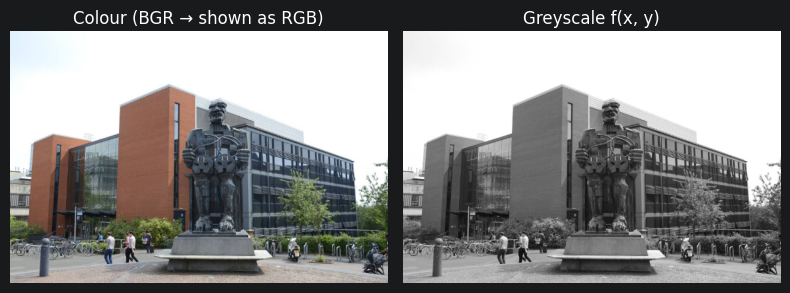

In [33]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

plt.rcParams["figure.dpi"] = 100

def show(images, titles=None, cmap="gray", size=4):
    # Display several images side by side
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size))
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap=cmap, vmin=0, vmax=255 if im.max() > 1.0 else 1)
        if titles:
            ax.set_title(titles[i])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Load the photo, or build a test image if it isn't there
if os.path.exists("images/cs_building.png"):
    img_bgr = cv2.imread("images/cs_building.png")
else:
    print("cs_building.png not found, using a generated test image")
    img_bgr = np.zeros((400, 600, 3), np.uint8) #400 rows, 600 columns and 3 colour values per pixel.
    img_bgr[:] = (200, 170, 140) #[:] means “all of it”, every row and every column.
    #(200, 170, 140) is the colour written into each pixel. OpenCV stores colour as BGR, so this is Blue = 200, Green = 170, Red = 140.

    cv2.rectangle(img_bgr, (80, 120), (300, 360), (40, 60, 160), -1) # fill the box from column 80, row 120 to column 300, row 360 (220 wide × 240 tall). The colour is B=40, G=60, R=160 and the -1 means no outline: the whole shape is filled solid

    cv2.rectangle(img_bgr, (330, 160), (540, 360), (120, 110, 100), -1)
    cv2.circle(img_bgr, (300, 90), 50, (230, 230, 255), -1)
    for x in range(100, 290, 30):
        cv2.rectangle(img_bgr, (x, 150), (x + 15, 180), (220, 220, 220), -1)

gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)   # uint8, values 0..255
f = gray.astype(np.float32) / 255.0                 # float, values 0..1

print("colour image shape:", img_bgr.shape, " grey shape:", gray.shape)
show([img_bgr, gray], ["Colour (BGR → shown as RGB)", "Greyscale f(x, y)"])

---
# PART 1 — Lecture 3-1: Pixels, Arithmetic, Geometry, Histograms

## 1. The big picture: the image-processing pipeline (slide 2)

**In plain English:** this diagram is the "map" of the whole module. A raw photo goes through stages:

| Stage | What it does | Week you meet it |
|---|---|---|
| Image acquisition | camera turns light into numbers | Week 3 (now) |
| Filtering & enhancement | remove noise, improve contrast | Week 3 (now) |
| Transforms | rotate, scale, Fourier… | Week 3–4 |
| Segmentation | split image into regions/objects | later |
| Feature extraction | edges, corners, descriptors | Week 3 lab (edges) |
| Pattern classification | "this is a cat" | Week 7 (CNNs) |

The left half outputs **images**; the right half outputs **features** (numbers that describe the image). The "knowledge base" is just what we know about the problem, used at every stage.

## 2. Image formation and representation (slides 3–4)

**In plain English:** what the camera records at a point is *how much light hits the object* × *how much of it the object bounces back*. Then that continuous picture is chopped into a grid (pixels) and each pixel is rounded to a whole number.

**The maths**

$$f(x,y) = i(x,y)\, r(x,y)$$

- $i(x,y)$ — **illumination**: light falling on the scene (sun, lamp)
- $r(x,y)$ — **reflectance**: how much the surface reflects, between 0 (black velvet) and 1 (snow)
- $f(x,y)$ — the **digitised image** you get

Each intensity lies in a range $L_{min} \le \ell \le L_{max}$, usually **[0, 255]** (8-bit) or **[0, 1]** (float).

The image is an $M \times N$ **matrix**, with $a_{ij} = f(i,j)$. **Row first, then column**, and the origin $(0,0)$ is the **top-left**. The centre is $(\lfloor M/2 \rfloor, \lfloor N/2 \rfloor)$.

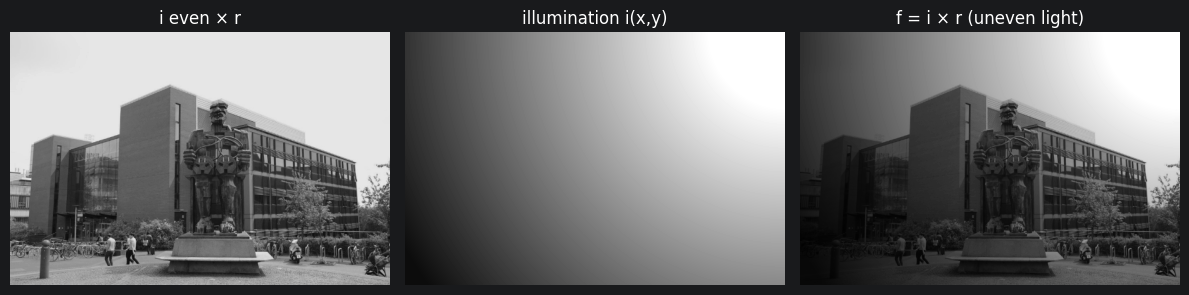

Top-left 5x5 pixel values (a_ij = f(i, j)):
 [[238 238 238 238 238]
 [238 238 238 238 238]
 [238 238 238 238 238]
 [238 237 237 238 238]
 [238 238 237 238 238]]
Pixel at row 10, column 20: 241
Image centre (floor(M/2), floor(N/2)) = (200, 300)
As a tensor: torch.Size([1, 1, 400, 600])   min/max: 0.0235294122248888 1.0


In [34]:
# f = i * r : same object (reflectance) under two different lights (illumination)
M, N = gray.shape
r = f.copy()                                        # pretend our photo is pure reflectance
yy, xx = np.mgrid[0:M, 0:N]
i_even   = np.full((M, N), 0.9, np.float32)         # bright, even light
i_corner = np.clip(1.2 - np.hypot(xx - N, yy) / N, 0.05, 1).astype(np.float32)  # lamp in top-right

show([i_even * r, i_corner, i_corner * r],
     ["i even × r", "illumination i(x,y)", "f = i × r (uneven light)"])

# The image is literally a matrix
print("Top-left 5x5 pixel values (a_ij = f(i, j)):\n", gray[:5, :5])
print("Pixel at row 10, column 20:", gray[10, 20])
print("Image centre (floor(M/2), floor(N/2)) =", (M // 2, N // 2))

# The same matrix as a PyTorch tensor: (H, W) -> (batch, channels, H, W)
t = torch.from_numpy(f)[None, None]
print("As a tensor:", t.shape, "  min/max:", t.min().item(), t.max().item())

## 3. Arithmetic operations between images (slides 5–9)

**In plain English:** two images of the same size can be added, subtracted, multiplied and divided **pixel by pixel**, as if they were two spreadsheets.

| Operation | Equation | Real-world use |
|---|---|---|
| Addition | $s(x,y)=f(x,y)+g(x,y)$ | **Noise reduction** (average many shots) |
| Subtraction | $d(x,y)=f(x,y)-g(x,y)$ | **Change detection** (what moved?) |
| Product | $p(x,y)=f(x,y)\times g(x,y)$ | **Masking** (keep only a region) |
| Division | $v(x,y)=f(x,y)\div g(x,y)$ | **Shading correction** (remove uneven light) |


### 3a. Addition → noise reduction by averaging (slide 6)

**The core idea:** noise is random — sometimes it pushes a pixel up, sometimes down.
If you **average several noisy measurements of the same thing**, the ups and downs
cancel out, but the true value stays. Image processing uses this idea in two ways.

#### Way 1 — Average across K images (temporal averaging) ← *this is slide 6*

Take $K$ photos of the **same, still scene**. Each one is the true image plus its own random noise:

$$g_i(x,y) = f(x,y) + \eta_i(x,y), \qquad i = 1, \dots, K$$

where $\eta_i$ has mean 0. Add them up and divide by $K$:

$$\bar g(x,y) = \frac{1}{K}\sum_{i=1}^{K} g_i(x,y), \qquad E\{\bar g\} = f, \qquad \sigma^2_{\bar g} = \frac{1}{K}\,\sigma^2_{\eta}$$

- $E\{\bar g\} = f$ → on average, the result **is** the true image (no bias)
- $\sigma^2_{\bar g} = \sigma^2_\eta / K$ → the **noise variance shrinks by a factor of K**

✅ Removes noise **without blurring**, because each pixel is only averaged with itself.
❌ Needs many shots of a scene that doesn't move.
**Used in:** astrophotography, phone "night mode", medical scans.

#### Way 2 — Average across neighbours in ONE image (spatial averaging)

Often you only have **one** photo. Then you average each pixel with its $k \times k$
neighbourhood instead. This is the **box filter** (arithmetic mean filter, Section 5 and Section 13):

$$\hat f(x,y) = \frac{1}{k^2}\sum_{(r,c)\in S_{xy}} g(r,c)$$

Same maths, with $k^2$ neighbouring pixels playing the role of the $K$ images,
so the noise variance drops by roughly $k^2$.

✅ Works on a single image.
❌ **Blurs edges**, because neighbouring pixels aren't the same point of the scene.

| | Way 1: K images | Way 2: k×k neighbours |
|---|---|---|
| What is averaged | the same pixel across K shots | nearby pixels in one shot |
| Noise variance | $\sigma^2 / K$ | ≈ $\sigma^2 / k^2$ |
| Blurs edges? | No | Yes |
| Needs | many aligned photos | just one photo |

> ⚠️ **Don't confuse with K-Means.** K-Means clustering (ML module) also uses
> the letter $K$ and "means", but it is a different idea: it groups data points
> into $K$ clusters, each represented by the mean (centroid) of its points, and
> minimises the within-cluster sum of squared distances. It **groups data**;
> it does not remove noise.

K=  1: measured noise variance 0.06264   theory sigma²/K = 0.06250
K=  5: measured noise variance 0.01255   theory sigma²/K = 0.01250
K= 20: measured noise variance 0.00314   theory sigma²/K = 0.00313
K=100: measured noise variance 0.00063   theory sigma²/K = 0.00063


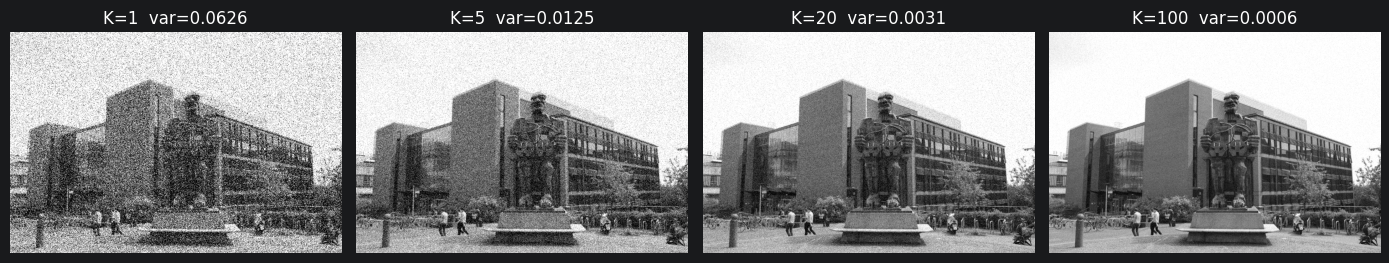

In [35]:
import numpy as np
rng = np.random.default_rng(0)
sigma = 0.25

def noisy_shot():
    return f + rng.normal(0, sigma, f.shape).astype(np.float32)

results, titles = [], []
for K in [1, 5, 20, 100]:
    g_bar = np.mean([noisy_shot() for _ in range(K)], axis=0)
    measured_var = np.var(g_bar - f)
    results.append(np.clip(g_bar, 0, 1))
    titles.append(f"K={K}  var={measured_var:.4f}")
    print(f"K={K:3d}: measured noise variance {measured_var:.5f}   theory sigma²/K = {sigma**2 / K:.5f}")

show(results, titles, size=3.5)

### 3b. Subtraction → change detection · 3c. Product → masking · 3d. Division → shading correction

- **Subtraction:** where two images are the same, $f-g=0$ (black). Anything that changed lights up. Used in CCTV motion detection and medical imaging (before/after contrast injection).
- **Product:** multiply by a mask that is 1 inside the region and 0 outside. Outside becomes 0 (black), inside is unchanged. This is the dental X-ray example.
- **Division:** if the image is $f = i \cdot r$ and you can estimate the lighting $i$ (e.g. photograph a blank white card), then $f / i = r$: the true surface with the uneven light removed. This is the chessboard example.

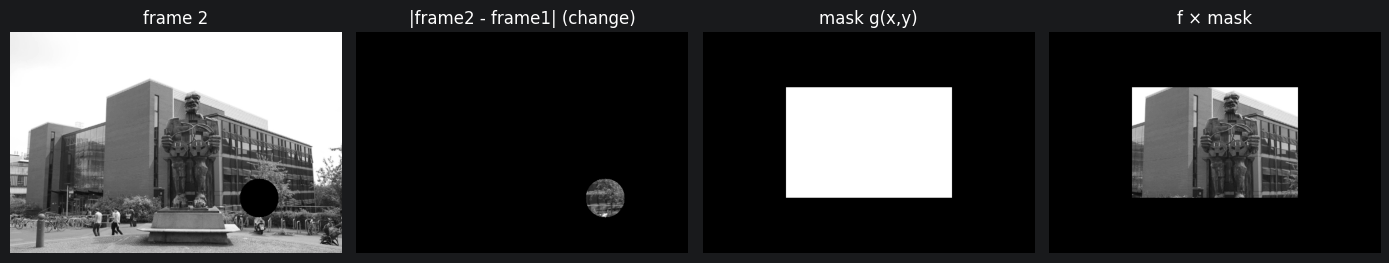

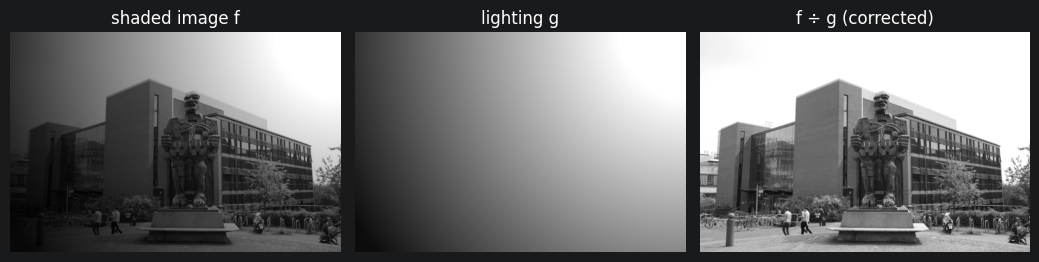

In [36]:
# --- Subtraction: something "appears" in the second frame ---
frame1 = gray.astype(np.int16)
frame2 = frame1.copy()
cv2.circle(frame2, (450, 300), 35, 0, -1)                 # a dark "object" appears
diff = np.abs(frame2 - frame1).astype(np.uint8)            # int16 avoids uint8 wrap-around
# OpenCV equivalent that handles the wrap-around for you: cv2.absdiff(img1, img2)

# --- Product: rectangular mask ---
mask = np.zeros_like(gray)
mask[100:300, 150:450] = 1
masked = gray * mask

# --- Division: remove uneven lighting ---
shaded = i_corner * r                                      # what the camera saw
corrected = shaded / (i_corner + 1e-6)                     # divide out the known lighting
# i_corner = np.clip(1.2 - np.hypot(xx - N, yy) / N, 0.05, 1).astype(np.float32)  # lamp in top-right
# f = i * r : same object (reflectance) under two different lights (illumination)
# r=f.copy()

show([frame2.astype(np.uint8), diff, mask * 255, masked],
     ["frame 2", "|frame2 - frame1| (change)", "mask g(x,y)", "f × mask"], size=3.5)
show([shaded, i_corner, np.clip(corrected, 0, 1)],
     ["shaded image f", "lighting g", "f ÷ g (corrected)"], size=3.5)

## 4. Single-pixel operations (slide 10)

**In plain English:** each output pixel depends **only on the same input pixel**. You apply one rule $T$ to every value independently.

**The maths:** $s = T(z)$, where $z$ is the input intensity and $s$ the output.

The example is the **image negative**:

$$s = T(z) = L - 1 - z \quad (\text{with } L-1 = 255)$$

Intensity = كم البكسل فاتح أو غامق. يعني رقم واحد يمثّل سطوع البكسل، وبس.
So black (0) → white (255) → Gray (125). Radiologists use it because small dark details are easier to see on a light background (the mammogram on the slide).

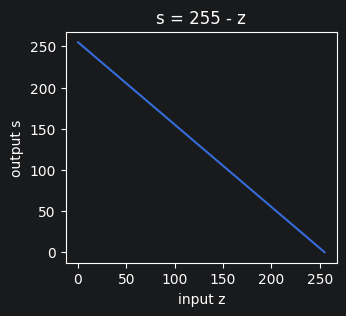

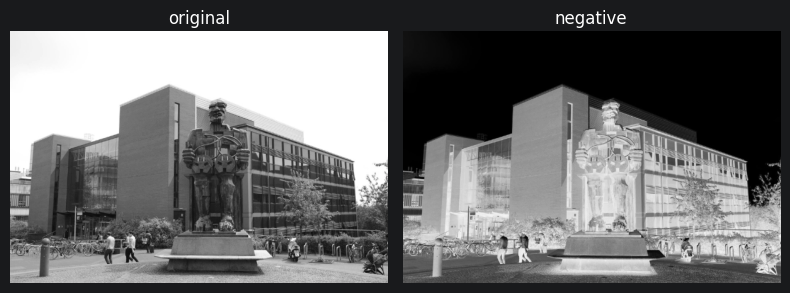

In [37]:
L = 256 #is the number of intensity levels
# max intensity = L - 1 = 255
# gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)   # uint8, values 0..255
negative = (L - 1) - gray            # works on the whole matrix at once

# The transformation curve T(z) from the slide
z = np.arange(256)
plt.figure(figsize=(3.5, 3)); plt.plot(z, 255 - z); plt.xlabel("input z"); plt.ylabel("output s")
plt.title("s = 255 - z"); plt.show()

show([gray, negative], ["original", "negative"])

## 5. Neighbourhood operations (slide 11)

**In plain English:** now each output pixel depends on a **small window of pixels around it**, not just itself. The simplest version averages that window, which blurs the image.

**The maths:**

$$g(x,y) = \frac{1}{mn} \sum_{(r,c)\in S_{xy}} f(r,c)$$

- $S_{xy}$ — the $m \times n$ window centred on $(x,y)$
- $\frac{1}{mn}\sum$ — add up all pixels in the window and divide by how many there are (the average)

This idea of a **sliding window** is the foundation for all of Lecture 3-2 *and* for CNNs.

5x5 window around (200, 300):
 [[ 71  77  78  83  83]
 [ 73  81  85  82  83]
 [ 98 102  92  88  92]
 [169 147  63  64  62]
 [161 143  52  60  71]]
g(200, 300) = mean of window = 90.4
cv2.blur result at (200, 300): 90
PyTorch avg_pool2d at (200, 300): 90.4000015258789


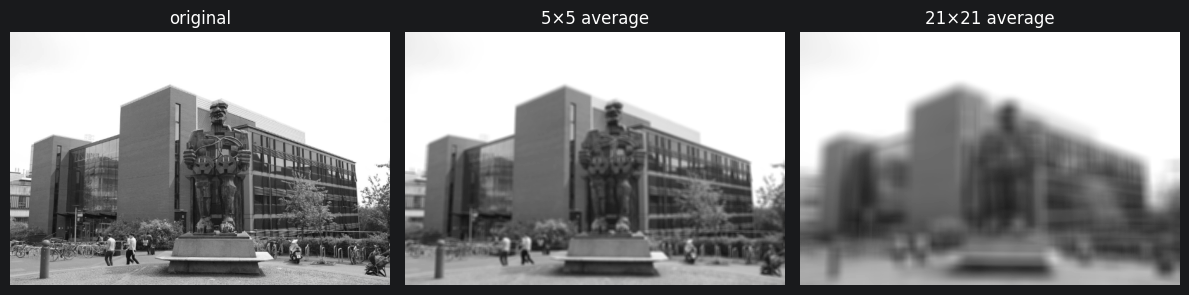

In [52]:
# Manual version for ONE pixel, to see the formula working
x, y, m = 200, 300, 5
h = m // 2
window = gray[x - h:x + h + 1   ,   y - h:y + h + 1].astype(np.float32)
print("5x5 window around (200, 300):\n", window.astype(int))
print("g(200, 300) = mean of window =", window.mean())

# OpenCV does it for every pixel at once
blur5  = cv2.blur(gray, (5, 5))
blur21 = cv2.blur(gray, (21, 21))
print("cv2.blur result at (200, 300):", blur5[x, y])

# PyTorch: average pooling with stride 1 is exactly this operation
pooled = F.avg_pool2d(torch.from_numpy(gray).float()[None, None], kernel_size=5, stride=1, padding=2)
print("PyTorch avg_pool2d at (200, 300):", pooled[0, 0, x, y].item())

show([gray, blur5, blur21], ["original", "5×5 average", "21×21 average"])

## 6. Distance metrics (slides 12–13)

**In plain English:** "how far apart are two pixels?" has three common answers, depending on how you're allowed to move across the grid.

For pixels $p=(x,y)$ and $q=(u,v)$:

| Name | Equation | Think of it as |
|---|---|---|
| **Euclidean** $D_e$ | $\sqrt{(x-u)^2+(y-v)^2}$ | a straight line, "as the crow flies" |
| **City-block** $D_4$ | $\lvert x-u\rvert+\lvert y-v\rvert$ | a taxi on a grid: only up/down/left/right |
| **Chessboard** $D_8$ | $\max(\lvert x-u\rvert, \lvert y-v\rvert)$ | a chess king: diagonals cost the same as straight moves |

Any valid distance must obey three rules: $D \ge 0$ (and $=0$ only for the same pixel); $D(p,q)=D(q,p)$; and the triangle inequality $D(p,s) \le D(p,q)+D(q,s)$ (a detour is never shorter).

The grids on slide 13 show the distance of every pixel from the centre. City-block makes a **diamond**, chessboard a **square**, Euclidean a **circle**.

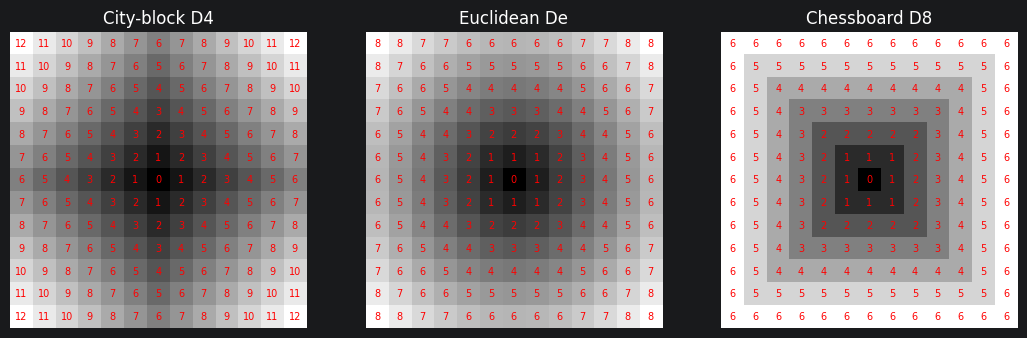

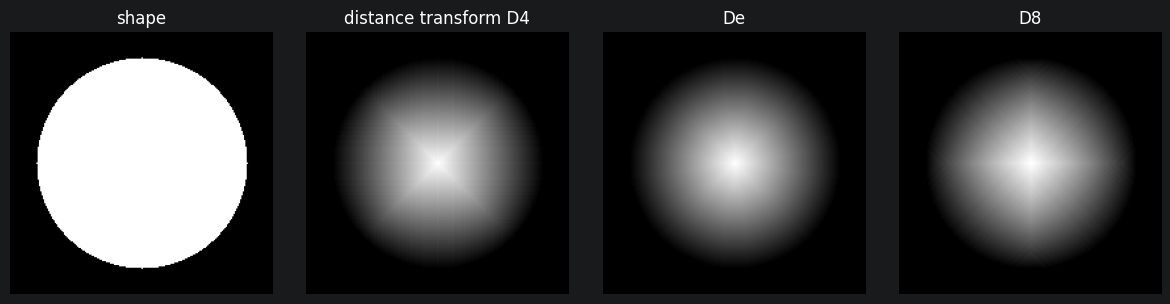

In [39]:
size, c = 13, 6
u, v = np.mgrid[0:size, 0:size]  #creates two grids that hold the coordinates of every pixel one for row, and one for column
D_e = np.sqrt((u - c) ** 2 + (v - c) ** 2)
D_4 = np.abs(u - c) + np.abs(v - c)
D_8 = np.maximum(np.abs(u - c), np.abs(v - c))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, D, name in zip(axes, [D_4, D_e, D_8], ["City-block D4", "Euclidean De", "Chessboard D8"]):
    ax.imshow(D, cmap="gray")
    for i in range(size):
        for j in range(size):
            ax.text(j, i, f"{D[i, j]:.0f}", ha="center", va="center", color="red", fontsize=7)
    ax.set_title(name); ax.axis("off")
plt.show()

# Real use: distance transform = "how far is each pixel from the nearest black pixel?"
# Used in robotics path planning and in separating touching objects.
binary = np.zeros((200, 200), np.uint8)
cv2.circle(binary, (100, 100), 80, 255, -1)
dt_L1 = cv2.distanceTransform(binary, cv2.DIST_L1, 3)   # city-block
dt_L2 = cv2.distanceTransform(binary, cv2.DIST_L2, 5)   # Euclidean
dt_C  = cv2.distanceTransform(binary, cv2.DIST_C, 3)    # chessboard
show([binary, dt_L1 / dt_L1.max(), dt_L2 / dt_L2.max(), dt_C / dt_C.max()],
     ["shape", "distance transform D4", "De", "D8"], size=3)

## 7. Neighbours, adjacency and connectivity (slides 14–18)

**In plain English:** which pixels count as "touching" a pixel $p=(x,y)$?

- **4-neighbours** (sharing an edge): $N_4(p) = \{(x\pm1,y),\ (x,y\pm1)\}$
- **Diagonal neighbours** (sharing only a corner): $N_D(p) = \{(x\pm1,y\pm1)\}$
- **8-neighbours** (all of them): $N_8(p) = N_4(p) \cup N_D(p)$

**Adjacency** adds a condition: both pixels must have a value from a set $V$ (in a binary image $V=\{1\}$, i.e. both are "on").

- **4-adjacent:** $q \in N_4(p)$
- **8-adjacent:** $q \in N_8(p)$
- **m-adjacent (mixed):** $q \in N_4(p)$, **or** $q \in N_D(p)$ *and* the pixels they share, $N_4(p)\cap N_4(q)$, are not in $V$. It uses a diagonal only when there is no straight route. This removes the "double path" ambiguity of 8-adjacency (slide 17).

**Why it matters:** a **path** is a chain of adjacent pixels, and a **connected component** is a group of pixels that can all reach each other. Counting objects ("how many coins in this photo?") is counting connected components, and the answer **depends on whether you use 4 or 8 connectivity**.

4-connectivity objects: 2
[[0 0 0 0 0 0]
 [0 1 1 0 0 0]
 [0 1 1 0 0 0]
 [0 0 0 2 2 0]
 [0 0 0 2 2 0]
 [0 0 0 0 0 0]]
8-connectivity objects: 1
[[0 0 0 0 0 0]
 [0 1 1 0 0 0]
 [0 1 1 0 0 0]
 [0 0 0 1 1 0]
 [0 0 0 1 1 0]
 [0 0 0 0 0 0]]

Bright regions found in the photo: 440


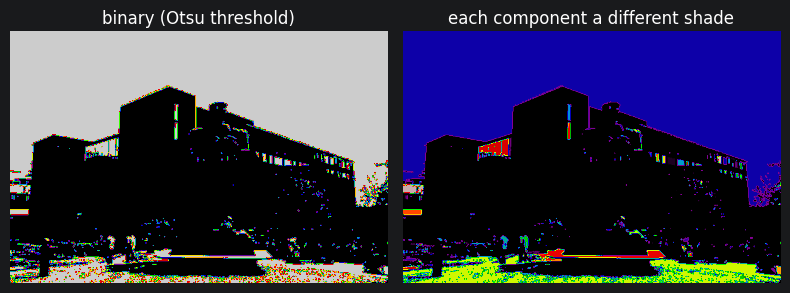

In [40]:
# Two blobs that touch only diagonally
pix = np.array([[0, 0, 0, 0, 0, 0],
                [0, 1, 1, 0, 0, 0],
                [0, 1, 1, 0, 0, 0],
                [0, 0, 0, 1, 1, 0],
                [0, 0, 0, 1, 1, 0],
                [0, 0, 0, 0, 0, 0]], np.uint8)

n4, labels4 = cv2.connectedComponents(pix, connectivity=4)
n8, labels8 = cv2.connectedComponents(pix, connectivity=8)
print("4-connectivity objects:", n4 - 1)   # minus 1 because label 0 is the background
print(labels4)
print("8-connectivity objects:", n8 - 1)
print(labels8)

# Real use: count bright blobs in the photo
_, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
n_obj, lab = cv2.connectedComponents(bw, connectivity=8)
print("\nBright regions found in the photo:", n_obj - 1)
show([bw, (lab * 37 % 255).astype(np.uint8)], ["binary (Otsu threshold)", "each component a different shade"],
     cmap="nipy_spectral")

### Foreground, background and contours (slides 19–21)

- **Foreground** $R_u$: the union of all regions (the "on" pixels). **Background** $(R_u)^c$: everything else.
- **Contour (boundary):** the pixels **in** the region that have **at least one background neighbour**.

Which neighbours you check changes the contour. Checking 8-neighbours (diagonals included) flags more pixels, giving a **thicker** contour. Checking only 4-neighbours gives a **thinner** one. That is slide 21.

**Neat trick:** contour = region − (region shrunk by one pixel). Shrinking is called *erosion*, and the shape of the erosion kernel decides 4 vs 8.

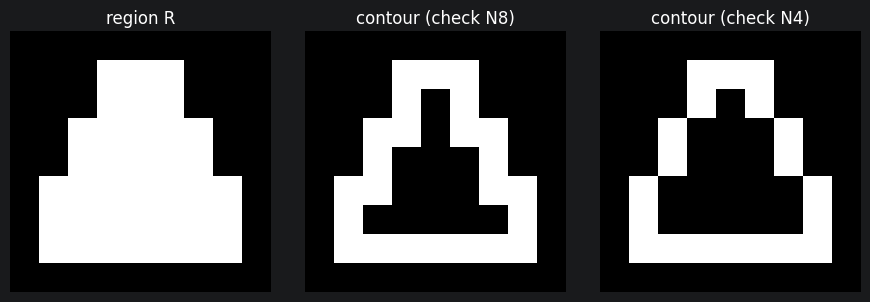

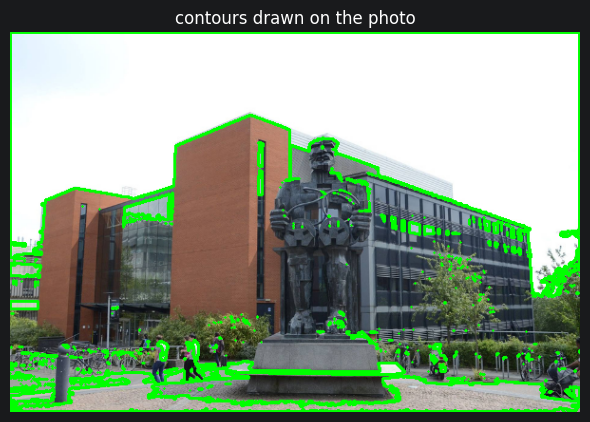

In [41]:
region = np.zeros((9, 9), np.uint8)
region[1:3, 3:6] = 1; region[3:5, 2:7] = 1; region[5:8, 1:8] = 1   # stepped triangle like slide 21

cross  = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], np.uint8)  # looks at N4
square = np.ones((3, 3), np.uint8)                               # looks at N8

contour_8 = region - cv2.erode(region, square)  # bg neighbour among 8-neighbours
contour_4 = region - cv2.erode(region, cross)   # bg neighbour among 4-neighbours
show([region, contour_8, contour_4], ["region R", "contour (check N8)", "contour (check N4)"], size=3)

# Real use: OpenCV's contour finder on the photo's binary mask
contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
outlined = img_bgr.copy()
cv2.drawContours(outlined, contours, -1, (0, 255, 0), 2)
show([outlined], ["contours drawn on the photo"], size=6)

## 8. Geometric transformations (slides 22–23)

**In plain English:** these don't change pixel *values*; they change pixel *positions*: move, rotate, scale, shear, flip.

**The maths:** every pixel coordinate is multiplied by a matrix. To include *translation* (shifting), a 1 is appended to the coordinate, which makes a **3×3 affine matrix** (homogeneous coordinates):

$$\begin{bmatrix}x'\\y'\\1\end{bmatrix} = A\begin{bmatrix}x\\y\\1\end{bmatrix} = \begin{bmatrix}a_{11}&a_{12}&a_{13}\\a_{21}&a_{22}&a_{23}\\0&0&1\end{bmatrix}\begin{bmatrix}x\\y\\1\end{bmatrix}$$

| Transform | Matrix $A$ | Effect |
|---|---|---|
| Identity | $\begin{bmatrix}1&0&0\\0&1&0\\0&0&1\end{bmatrix}$ | nothing |
| Scale / reflect | $\begin{bmatrix}c_x&0&0\\0&c_y&0\\0&0&1\end{bmatrix}$ | $x'=c_xx$; use $-1$ to flip |
| Rotate | $\begin{bmatrix}\cos\theta&-\sin\theta&0\\\sin\theta&\cos\theta&0\\0&0&1\end{bmatrix}$ | turn by $\theta$ |
| Translate | $\begin{bmatrix}1&0&t_x\\0&1&t_y\\0&0&1\end{bmatrix}$ | $x'=x+t_x$ |
| Shear | $\begin{bmatrix}1&s_v&0\\0&1&0\\0&0&1\end{bmatrix}$ | slant |

**Big win:** to combine transforms, multiply their matrices into **one** matrix, then apply it once. OpenCV's `warpAffine` takes just the top two rows (a 2×3 matrix).

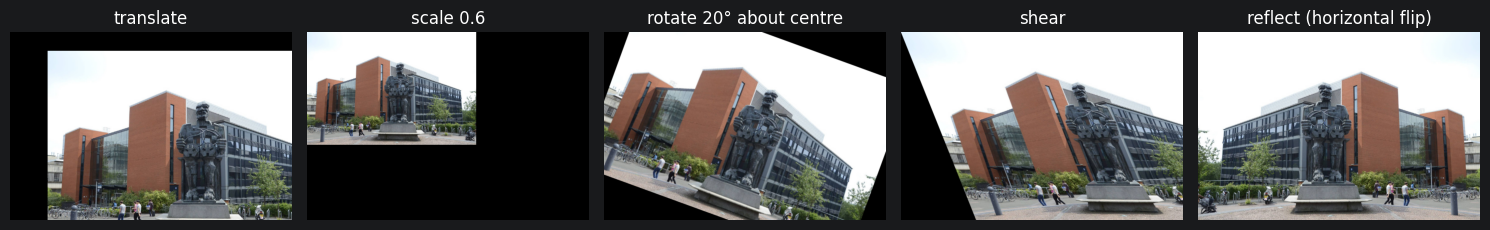

Hand-built matrix:
 [[  0.94   -0.342  86.496]
 [  0.342   0.94  -90.545]]
cv2.getRotationMatrix2D:
 [[  0.94   -0.342  86.496]
 [  0.342   0.94  -90.545]]


In [54]:
h_img, w_img = gray.shape

def warp(A3):
    # cv2.warpAffine uses the top 2 rows of the 3x3 matrix; OpenCV coordinates are (x=column, y=row)
    return cv2.warpAffine(img_bgr, A3[:2].astype(np.float32), (w_img, h_img))

T_translate = np.array([[1, 0, 80], [0, 1, 40], [0, 0, 1]])
T_scale     = np.array([[0.6, 0, 0], [0, 0.6, 0], [0, 0, 1]])
T_shear     = np.array([[1, 0.4, 0], [0, 1, 0], [0, 0, 1]])
T_flip      = np.array([[-1, 0, w_img - 1], [0, 1, 0], [0, 0, 1]])  # reflect, then shift back into view

theta = np.deg2rad(20)
cx, cy = w_img / 2, h_img / 2
to_origin = np.array([[1, 0, -cx], [0, 1, -cy], [0, 0, 1]])
rotate    = np.array([[np.cos(theta), -np.sin(theta), 0], [np.sin(theta), np.cos(theta), 0], [0, 0, 1]])
back      = np.array([[1, 0, cx], [0, 1, cy], [0, 0, 1]])
T_rotate_centre = back @ rotate @ to_origin   # read right to left: move to origin, rotate, move back

show([warp(T_translate), warp(T_scale), warp(T_rotate_centre), warp(T_shear), warp(T_flip)],
     ["translate", "scale 0.6", "rotate 20° about centre", "shear", "reflect (horizontal flip)"], size=3)

# OpenCV builds the rotation-about-centre matrix for you:
print("Hand-built matrix:\n", T_rotate_centre[:2].round(3))
print("cv2.getRotationMatrix2D:\n", cv2.getRotationMatrix2D((cx, cy), -20, 1.0).round(3))

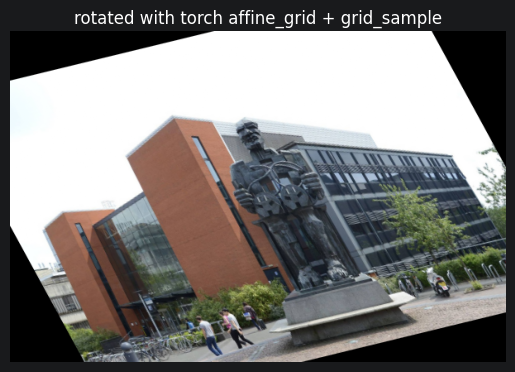

In [43]:
# PyTorch version — this is what data augmentation (random rotate/scale) does inside a training pipeline
x_t = torch.from_numpy(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float()[None] / 255

th = torch.tensor([[[np.cos(theta), -np.sin(theta), 0.0],
                    [np.sin(theta),  np.cos(theta), 0.0]]], dtype=torch.float32)
grid = F.affine_grid(th, x_t.shape, align_corners=False)   # where each output pixel samples from
rotated_t = F.grid_sample(x_t, grid, align_corners=False)

plt.imshow(rotated_t[0].permute(1, 2, 0).clamp(0, 1).numpy()); plt.axis("off")
plt.title("rotated with torch affine_grid + grid_sample"); plt.show()

## 9. Histograms, contrast stretching and equalisation (slides 24–28)

**In plain English:** a histogram counts how many pixels have each brightness. It tells you at a glance whether an image is dark, bright, low-contrast or high-contrast (slide 25):

- **dark** → bars bunched on the left
- **bright** → bunched on the right
- **low contrast** → bunched in a narrow band
- **high contrast** → spread across the whole range

**The maths:** for intensities $r_k$, $k = 0 \dots L-1$:

$$h(r_k) = n_k \quad \text{(number of pixels with value } r_k\text{)}, \qquad p(r_k) = \frac{n_k}{MN}$$

$p(r_k)$ is the *normalised* histogram: the probability that a random pixel has value $r_k$. It sums to 1.

### Contrast stretching (slide 26)
Take the narrow range $[r_{min}, r_{max}]$ and stretch it linearly to fill $[0, L-1]$:

$$s = (L-1)\,\frac{r - r_{min}}{r_{max} - r_{min}}$$

### Histogram equalisation (slides 27–28)
Smarter than a straight-line stretch: values where **lots of pixels are crowded** get spread further apart. The mapping is the **cumulative** histogram (CDF):

$$T(r_k) = (L-1)\sum_{j=0}^{k} p_r(r_j)$$

$T$ always increases, so the brightness order is never swapped, and the output histogram becomes roughly flat. Used heavily in medical imaging (X-rays, CT) and on low-light photos.

sum of normalised histogram = 0.9999999999999999
slide formula: darkest output = 0  (CDF never starts at 0)
OpenCV variant matches cv2.equalizeHist (max diff): 0


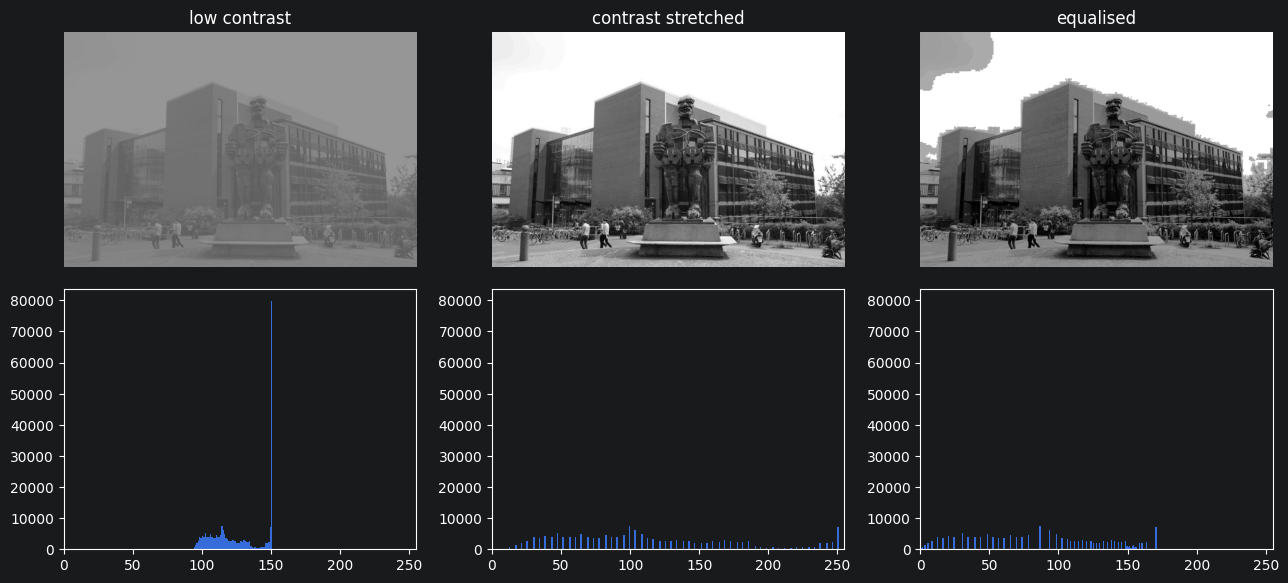

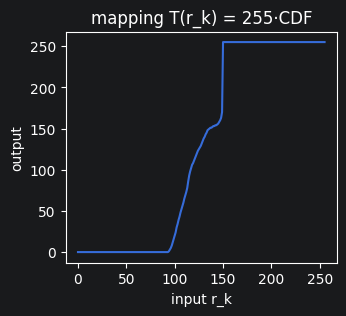

In [44]:
# Simulate a washed-out, low-contrast version of the photo (values squeezed into 90..150)
low = (90 + gray.astype(np.float32) * (60 / 255)).astype(np.uint8)

# --- Histogram, by hand and with OpenCV ---
h_counts = np.bincount(low.ravel(), minlength=256)        # h(r_k) = n_k
p = h_counts / low.size                                   # p(r_k) = n_k / MN
print("sum of normalised histogram =", p.sum())
assert np.array_equal(h_counts, cv2.calcHist([low], [0], None, [256], [0, 256]).ravel().astype(int))

# --- Contrast stretching ---
r_min, r_max = low.min(), low.max()
stretched = ((low.astype(np.float32) - r_min) / (r_max - r_min) * 255).astype(np.uint8)

# --- Histogram equalisation by hand: T = (L-1) * CDF ---
cdf = np.cumsum(p)
T = np.round(255 * cdf).astype(np.uint8)   # lookup table: old value -> new value
equalised = T[low]                         # apply it to every pixel

equalised_cv = cv2.equalizeHist(low)       # OpenCV's built-in
# OpenCV uses a slightly tweaked formula so the darkest value maps to exactly 0:
#   T = (L-1) * (CDF - CDF_min) / (1 - CDF_min)
cdf_min = cdf[cdf > 0].min()
T_cv = np.round(255 * (cdf - cdf_min) / (1 - cdf_min)).clip(0, 255).astype(np.uint8)
print("slide formula: darkest output =", equalised.min(), " (CDF never starts at 0)")
print("OpenCV variant matches cv2.equalizeHist (max diff):",
      np.abs(T_cv[low].astype(int) - equalised_cv).max())

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for col, (im, name) in enumerate([(low, "low contrast"), (stretched, "contrast stretched"), (equalised, "equalised")]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, col].set_title(name); axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=256, range=(0, 256)); axes[1, col].set_xlim(0, 255)
plt.tight_layout(); plt.show()

plt.figure(figsize=(3.5, 3)); plt.plot(T); plt.title("mapping T(r_k) = 255·CDF")
plt.xlabel("input r_k"); plt.ylabel("output"); plt.show()

---
# PART 2 — Lecture 3-2: Spatial Filtering

## 10. What "filtering" means (slide 33)

**In plain English:** an image has **low frequencies** (smooth, slowly changing areas like sky) and **high frequencies** (sudden changes: edges, fine texture, *and noise*).

- **Low-pass filter** → keeps the smooth part → **blurs** (smoothing, denoising)
- **High-pass filter** → keeps the changes → **sharpens / finds edges**
- Band-pass / band-reject → keep or remove a middle range

In the *spatial* domain we do this with a **kernel**: a small grid of weights slid across the image.

## 11. Linear spatial filtering: correlation vs convolution (slides 34–37)

**In plain English:** place the kernel's centre on a pixel, multiply each kernel weight by the pixel underneath it, add the results up, and write that number to the output. Slide one pixel along and repeat. It's the neighbourhood average from Section 5, but with **any** weights.

**The maths (correlation):**

$$g(x,y) = \sum_{s=-a}^{a}\sum_{t=-b}^{b} w(s,t)\, f(x+s,\ y+t)$$

- $w$ — the $m\times n$ kernel ($m=2a+1$, $n=2b+1$, so for a 3×3 kernel $a=b=1$)
- $w(0,0)$ — the kernel centre, which sits on $f(x,y)$

**Convolution** is identical except the kernel is **rotated 180°** first:

$$g(x,y) = \sum_{s}\sum_{t} w(s,t)\, f(x-s,\ y-t)$$

**Why two versions?** Slides 36–37 show it. Run correlation over a single "1" (an *impulse*) and you get the kernel back **upside down**. Convolution gives the kernel back **the right way round**. If the kernel is symmetric (mean, Gaussian, Laplacian), the two are identical.

> ⚠️ **Exam trap:** `cv2.filter2D` and PyTorch's `nn.Conv2d` both actually compute **correlation**, despite the name "conv". For learned CNN kernels it doesn't matter, since the network just learns the flipped weights.

In [45]:
# 1-D example from slide 36
f1 = np.array([0, 0, 0, 1, 0, 0, 0, 0], float)
w1 = np.array([1, 2, 4, 2, 8], float)

correlation = np.correlate(f1, w1, mode="same")
convolution = np.convolve(f1, w1, mode="same")
print("correlation:", correlation.astype(int), "  <- kernel comes out reversed (8 2 4 2 1)")
print("convolution:", convolution.astype(int), "  <- kernel comes out as-is (1 2 4 2 8)")

# 2-D example from slide 37
f2 = np.zeros((5, 5), np.float32); f2[2, 2] = 1          # an impulse
w2 = np.arange(1, 10, dtype=np.float32).reshape(3, 3)     # 1..9

corr2 = cv2.filter2D(f2, -1, w2, borderType=cv2.BORDER_CONSTANT)
conv2 = cv2.filter2D(f2, -1, np.rot90(w2, 2), borderType=cv2.BORDER_CONSTANT)  # rotate 180° → convolution
print("\n2-D correlation result (rotated kernel):\n", corr2[1:4, 1:4].astype(int))
print("2-D convolution result (original kernel):\n", conv2[1:4, 1:4].astype(int))

# PyTorch F.conv2d does the same as cv2.filter2D, i.e. correlation
torch_out = F.conv2d(torch.from_numpy(f2)[None, None], torch.from_numpy(w2)[None, None], padding=1)
print("\nPyTorch conv2d gives:\n", torch_out[0, 0, 1:4, 1:4].int().numpy(), "  -> same as correlation!")

correlation: [0 8 2 4 2 1 0 0]   <- kernel comes out reversed (8 2 4 2 1)
convolution: [0 1 2 4 2 8 0 0]   <- kernel comes out as-is (1 2 4 2 8)

2-D correlation result (rotated kernel):
 [[9 8 7]
 [6 5 4]
 [3 2 1]]
2-D convolution result (original kernel):
 [[1 2 3]
 [4 5 6]
 [7 8 9]]

PyTorch conv2d gives:
 [[9 8 7]
 [6 5 4]
 [3 2 1]]   -> same as correlation!


## 12. The image degradation model and noise (slides 38–44)

**In plain English:** real images get damaged in two ways, by **blur** (camera shake, out of focus) and by **noise** (sensor grain, transmission errors). Restoration means trying to undo that.

**The maths:**

$$g(x,y) = (h \star f)(x,y) + \eta(x,y)$$

- $f$ — the true, clean image (what we want)
- $h$ — the blur, applied by convolution ($\star$)
- $\eta$ — random noise
- $g$ — the damaged image we actually have

This week focuses on the **noise-only** case ($h$ = do nothing): $g = f + \eta$. Noise is treated as a random variable with a probability distribution (PDF), and **knowing which distribution tells you which filter to use**:

| Noise | Looks like | Random generator from slide 40 | Where it comes from |
|---|---|---|---|
| Gaussian | fine grain everywhere | $a + b\cdot\mathcal N(0,1)$ | sensor electronics, heat |
| Uniform | similar grain, flat PDF | $a + (b-a)\,\mathcal U(0,1)$ | quantisation |
| Rayleigh | grain skewed bright | $a+\sqrt{-b\ln(1-\mathcal U)}$ | range/radar imaging |
| Exponential / Gamma | skewed grain | $-\tfrac1a\ln(1-\mathcal U)$ | laser imaging |
| **Salt-and-pepper** | random pure black & white dots | pixel → 0 with prob $P_p$, → $L-1$ with prob $P_s$ | faulty pixels, bit errors |

Salt-and-pepper (slide 42): $P = P_s + P_p$ is the chance that a pixel gets corrupted.

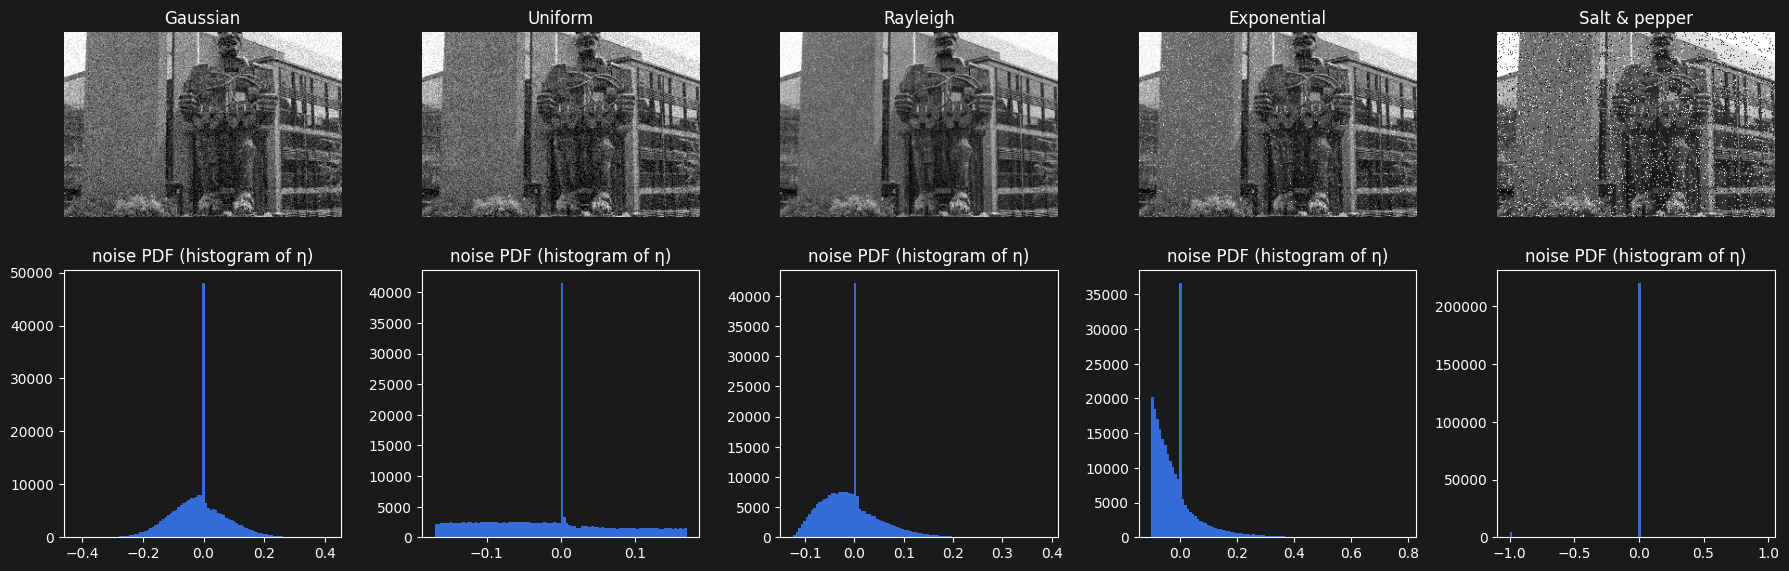

In [46]:
rng = np.random.default_rng(1)
U = lambda: rng.uniform(0, 1, f.shape)
N = lambda: rng.normal(0, 1, f.shape)

noise = {
    "Gaussian":    0.0 + 0.10 * N(),                                  # a + b·N(0,1)
    "Uniform":     -0.17 + 0.34 * U(),                                # a + (b-a)·U(0,1)
    "Rayleigh":    np.sqrt(-0.02 * np.log(1 - U())) - 0.125,           # shifted so mean ≈ 0
    "Exponential": -(1 / 10) * np.log(1 - U()) - 0.1,
}
noisy = {k: np.clip(f + v, 0, 1).astype(np.float32) for k, v in noise.items()}

def salt_pepper(img, Ps=0.05, Pp=0.05):
    out = img.copy()
    rnd = rng.uniform(0, 1, img.shape)
    out[rnd < Pp] = 0.0                       # pepper
    out[(rnd >= Pp) & (rnd < Pp + Ps)] = 1.0  # salt
    return out

noisy["Salt & pepper"] = salt_pepper(f)
crop = (slice(120, 320), slice(150, 450))

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for col, (name, im) in enumerate(noisy.items()):
    axes[0, col].imshow(im[crop], cmap="gray", vmin=0, vmax=1); axes[0, col].set_title(name); axes[0, col].axis("off")
    axes[1, col].hist((im - f).ravel(), bins=100); axes[1, col].set_title("noise PDF (histogram of η)")
plt.tight_layout(); plt.show()

g_gauss, g_sp = noisy["Gaussian"], noisy["Salt & pepper"]   # reused below

## 13. Mean filters — low-pass smoothing (slides 45–50)

**In plain English:** replace each pixel with some kind of *average* of its window. Noise is random, so it averages away. The price is that edges blur too.

All four use the $m\times n$ window $S_{xy}$. The **weights must sum to 1**, otherwise the whole image gets brighter or darker.

| Filter | Equation | Best for |
|---|---|---|
| **Arithmetic mean** (box) | $\hat f = \dfrac{1}{mn}\sum g(r,c)$ | Gaussian/uniform noise, simple blur |
| **Geometric mean** | $\hat f = \Big[\prod g(r,c)\Big]^{1/mn}$ | similar smoothing, keeps a bit more detail |
| **Harmonic mean** | $\hat f = \dfrac{mn}{\sum \frac{1}{g(r,c)}}$ | **salt** noise (fails on pepper) |
| **Contraharmonic** (order $Q$) | $\hat f = \dfrac{\sum g^{Q+1}}{\sum g^{Q}}$ | $Q>0$ kills **pepper**, $Q<0$ kills **salt** |

The box kernel is just a grid of $\frac{1}{mn}$: for 3×3, nine entries of $\frac19$.

**Contraharmonic intuition:** with $Q>0$, large values are boosted, so dark pepper dots get out-voted. With $Q<0$, small values dominate, so bright salt dots get out-voted. **Pick the wrong sign and you make it worse** (bottom row of slide 50).

Implementation trick: a product or a sum of reciprocals over a window can each be turned into an ordinary *window mean*, so `cv2.blur` does all the work.

box kernel sums to 1.0


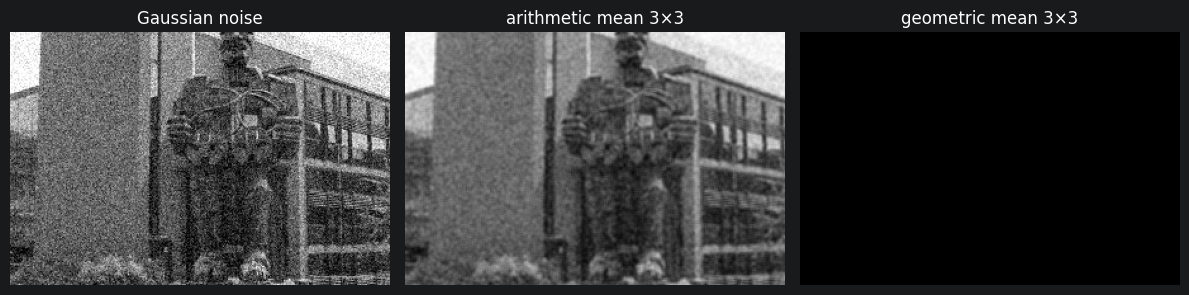

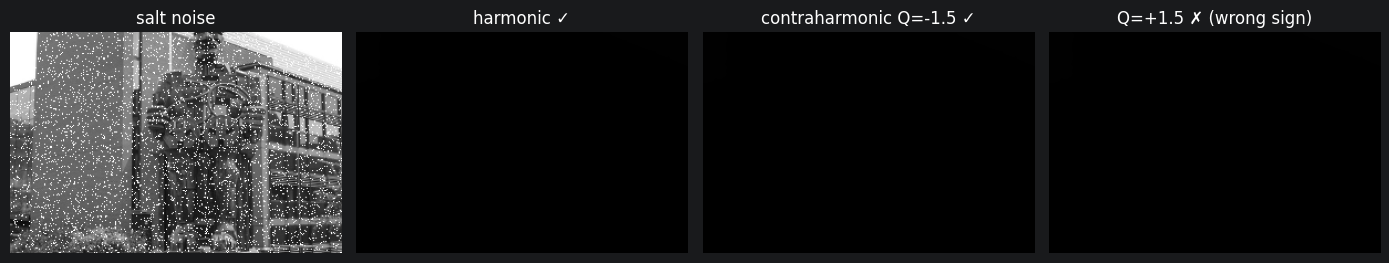

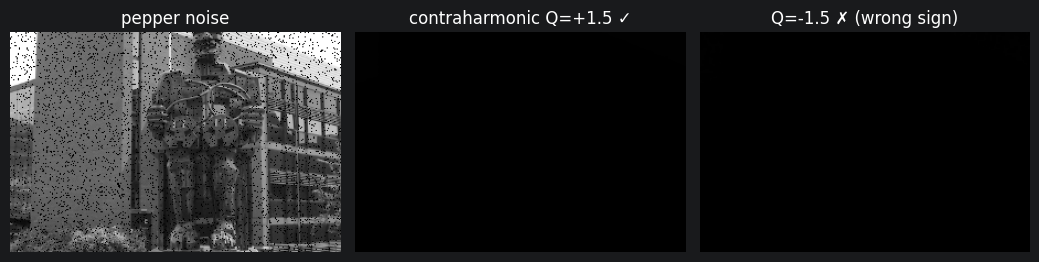

In [47]:
eps = 1e-6
k = (3, 3)

def arithmetic_mean(g):   return cv2.blur(g, k)
def geometric_mean(g):    return np.exp(cv2.blur(np.log(g + eps), k))        # (Π g)^(1/mn) = exp(mean(log g))
def harmonic_mean(g):     return 1.0 / cv2.blur(1.0 / (g + eps), k)          # mn / Σ(1/g) = 1 / mean(1/g)
def contraharmonic(g, Q): return cv2.blur((g + eps) ** (Q + 1), k) / cv2.blur((g + eps) ** Q, k)

# The box kernel itself, used via filter2D, gives the same as cv2.blur
box = np.ones((3, 3), np.float32) / 9
print("box kernel sums to", box.sum())
assert np.allclose(cv2.filter2D(g_gauss, -1, box), arithmetic_mean(g_gauss), atol=1e-5)

show([g_gauss[crop], arithmetic_mean(g_gauss)[crop], geometric_mean(g_gauss)[crop]],
     ["Gaussian noise", "arithmetic mean 3×3", "geometric mean 3×3"], size=4)

salt   = f.copy(); salt[rng.uniform(size=f.shape) < 0.08] = 1.0
pepper = f.copy(); pepper[rng.uniform(size=f.shape) < 0.08] = 0.0
show([salt[crop], harmonic_mean(salt)[crop], contraharmonic(salt, -1.5)[crop], contraharmonic(salt, +1.5)[crop]],
     ["salt noise", "harmonic ✓", "contraharmonic Q=-1.5 ✓", "Q=+1.5 ✗ (wrong sign)"], size=3.5)
show([pepper[crop], contraharmonic(pepper, +1.5)[crop], contraharmonic(pepper, -1.5)[crop]],
     ["pepper noise", "contraharmonic Q=+1.5 ✓", "Q=-1.5 ✗ (wrong sign)"], size=3.5)

## 14. The Gaussian filter (slides 51–52)

**In plain English:** a weighted average where **nearby pixels count more** than distant ones, following a bell curve. It blurs more naturally than the box filter (no blocky artefacts) and is the same in every direction (**isotropic**).

**The maths:**

$$w(s,t) = \frac{1}{k}\exp\!\left(-\frac{s^2+t^2}{2\sigma^2}\right)$$

- $(s,t)$ — offset from the kernel centre
- $\sigma$ — spread: bigger $\sigma$ means wider bell and more blur
- $k$ — the sum of all the raw values, so the weights add up to 1

Since $s^2+t^2=r^2$ (squared distance from the centre), the weight depends **only on distance**, which is why it's isotropic. The slide's 3×3 example with $\sigma=1$:

$$\frac{1}{4.8976}\begin{bmatrix}0.3679&0.6065&0.3679\\0.6065&1&0.6065\\0.3679&0.6065&0.3679\end{bmatrix}$$

raw 3x3 values (before ÷k):
 [[0.3679 0.6065 0.3679]
 [0.6065 1.     0.6065]
 [0.3679 0.6065 0.3679]]
k = 4.8976   <- matches 4.8976 on slide 51
max diff mine vs OpenCV : 0.0
max diff mine vs PyTorch: 0.0


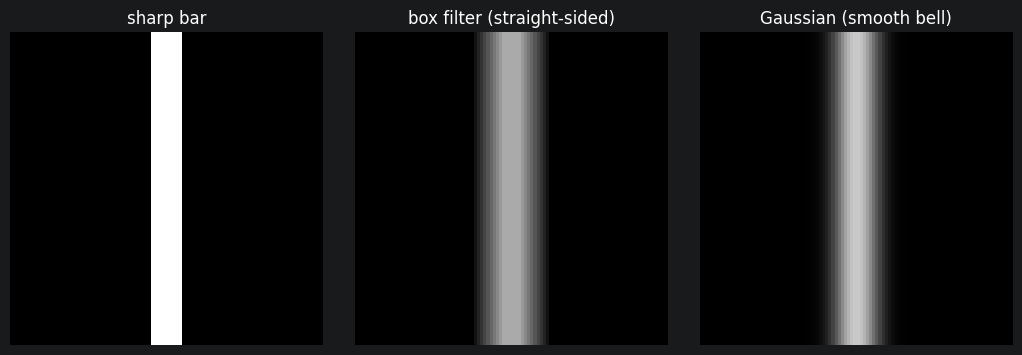

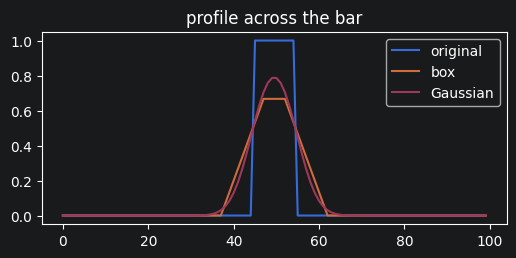

In [48]:
def gaussian_kernel(size, sigma):
    h = size // 2
    s, t = np.mgrid[-h:h + 1, -h:h + 1]
    raw = np.exp(-(s ** 2 + t ** 2) / (2 * sigma ** 2))
    return raw / raw.sum(), raw.sum()

G3, k_sum = gaussian_kernel(3, 1.0)
print("raw 3x3 values (before ÷k):\n", np.round(G3 * k_sum, 4))
print("k =", round(k_sum, 4), "  <- matches 4.8976 on slide 51")

# Apply: my kernel vs OpenCV vs PyTorch, all should agree
G, _ = gaussian_kernel(9, 2.0)
mine  = cv2.filter2D(g_gauss, -1, G.astype(np.float32))
cv_gb = cv2.GaussianBlur(g_gauss, (9, 9), 2.0)
torch_gb = F.conv2d(torch.from_numpy(g_gauss)[None, None],
                    torch.from_numpy(G.astype(np.float32))[None, None], padding=4)[0, 0].numpy()
print("max diff mine vs OpenCV :", np.abs(mine - cv_gb)[10:-10, 10:-10].max().round(6))
print("max diff mine vs PyTorch:", np.abs(mine - torch_gb)[10:-10, 10:-10].max().round(6))

# Box vs Gaussian on a sharp bar (slide 52)
bar = np.zeros((100, 100), np.float32); bar[:, 45:55] = 1
show([bar, cv2.blur(bar, (15, 15)), cv2.GaussianBlur(bar, (0, 0), 4)],
     ["sharp bar", "box filter (straight-sided)", "Gaussian (smooth bell)"], size=3.5)
plt.figure(figsize=(6, 2.5))
plt.plot(bar[50], label="original"); plt.plot(cv2.blur(bar, (15, 15))[50], label="box")
plt.plot(cv2.GaussianBlur(bar, (0, 0), 4)[50], label="Gaussian"); plt.legend(); plt.title("profile across the bar"); plt.show()

## 15. Order-statistics filters: median, max, min, midpoint (slides 53–57)

**In plain English:** instead of averaging the window, **sort** its values and pick one. These are **non-linear**: no kernel weights, so they can't be written as a convolution.

| Filter | Equation | Use |
|---|---|---|
| **Median** | $\hat f = \operatorname{median}\{g(r,c)\}$ | ⭐ **salt-and-pepper**: removes it almost perfectly while keeping edges sharp |
| **Max** (100th percentile) | $\hat f = \max\{g(r,c)\}$ | removes **pepper**; finds brightest points |
| **Min** (0th percentile) | $\hat f = \min\{g(r,c)\}$ | removes **salt**; finds darkest points |
| **Midpoint** | $\hat f = \tfrac12\big[\max + \min\big]$ | Gaussian / uniform noise |

**Why median beats mean on salt-and-pepper:** take a window `[10, 12, 11, 255, 13, 12, 11, 10, 12]`. The mean is 38, dragged up by the single 255. The median is 12. The extreme value simply loses the vote.

Fun fact: in OpenCV, max = `cv2.dilate` and min = `cv2.erode` (morphology, coming in a later week). PyTorch has max-pooling, which is the max filter that CNNs use.

mean = 38.4    median = 12.0


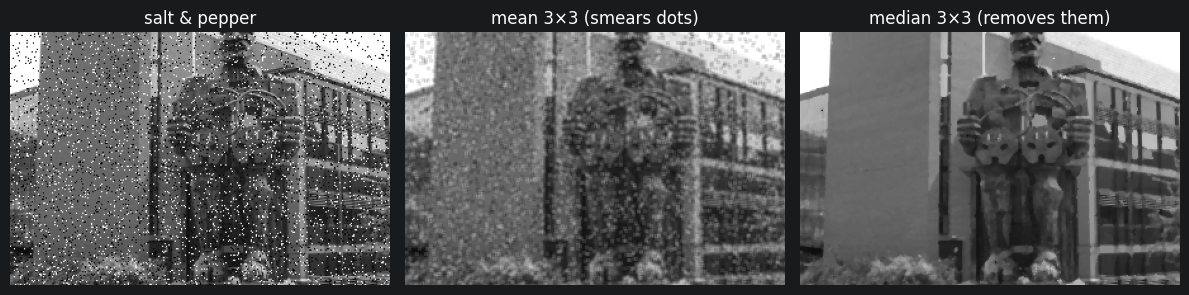

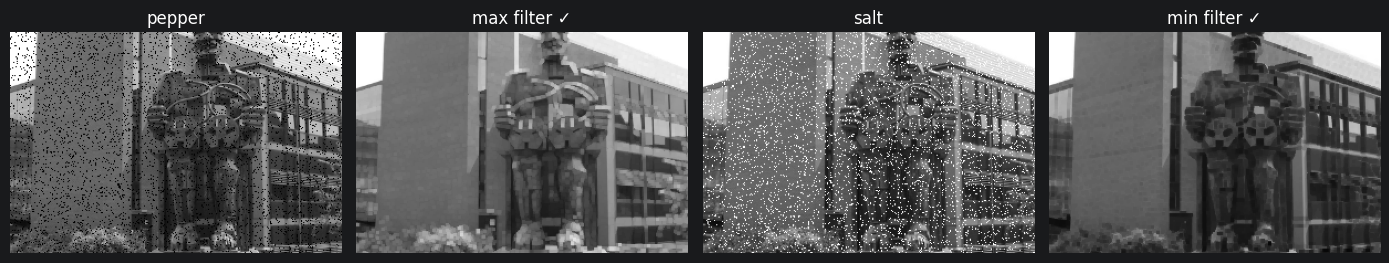

PyTorch max_pool2d == OpenCV dilate (interior): True


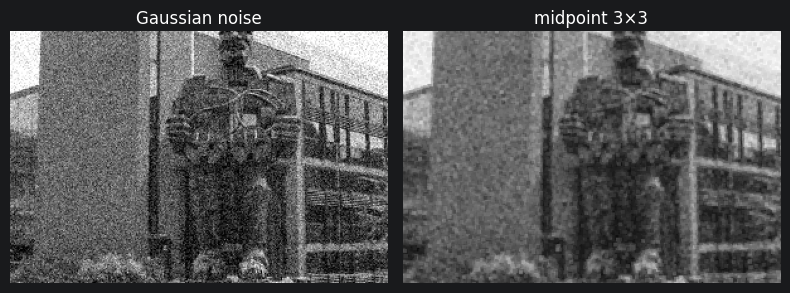

In [49]:
window = np.array([10, 12, 11, 255, 13, 12, 11, 10, 12])
print("mean =", window.mean().round(1), "   median =", np.median(window))

sp_u8 = (g_sp * 255).astype(np.uint8)
median = cv2.medianBlur(sp_u8, 3)
mean   = cv2.blur(sp_u8, (3, 3))
show([sp_u8[crop], mean[crop], median[crop]],
     ["salt & pepper", "mean 3×3 (smears dots)", "median 3×3 (removes them)"], size=4)

square = np.ones((3, 3), np.uint8)
pep_u8  = (pepper * 255).astype(np.uint8)
salt_u8 = (salt * 255).astype(np.uint8)
max_f = cv2.dilate(pep_u8, square)       # max filter
min_f = cv2.erode(salt_u8, square)       # min filter
show([pep_u8[crop], max_f[crop], salt_u8[crop], min_f[crop]],
     ["pepper", "max filter ✓", "salt", "min filter ✓"], size=3.5)

# Midpoint on Gaussian noise
gauss_u8 = (g_gauss * 255).astype(np.uint8)
midpoint = ((cv2.dilate(gauss_u8, square).astype(np.float32) + cv2.erode(gauss_u8, square)) / 2).astype(np.uint8)

# PyTorch: max filter = max_pool2d with stride 1; min = -max_pool(-x)
tp = torch.from_numpy(pep_u8).float()[None, None]
torch_max = F.max_pool2d(tp, 3, stride=1, padding=1)[0, 0].numpy()
print("PyTorch max_pool2d == OpenCV dilate (interior):", np.array_equal(torch_max[1:-1, 1:-1], max_f[1:-1, 1:-1]))
show([gauss_u8[crop], midpoint[crop]], ["Gaussian noise", "midpoint 3×3"], size=4)

## 16. Sharpening: high-pass filters with derivatives (slides 58–63)

**In plain English:** blurring = averaging ≈ **integration**. So the opposite, sharpening, ≈ **differentiation**: measure *how fast* brightness changes. Flat areas give 0 and edges give big numbers.

**The maths (discrete derivatives along one row):**

$$\frac{\partial f}{\partial x} = f(x+1) - f(x) \qquad\qquad \frac{\partial^2 f}{\partial x^2} = f(x+1) + f(x-1) - 2f(x)$$

| | 1st derivative | 2nd derivative |
|---|---|---|
| Flat area | 0 | 0 |
| Start of a ramp/step | non-zero | non-zero |
| **Along** a ramp | non-zero (constant) | **0** |
| End of a ramp/step | 0 | non-zero (opposite sign) |

So the 2nd derivative responds only at the **start and end** of a change, giving a double-edged response (a +ve and a −ve spike). That's what makes edges look crisp.

**The Laplacian** = 2nd derivative in $x$ + in $y$ (isotropic, so it doesn't care about edge direction):

$$\nabla^2 f(x,y) = f(x+1,y)+f(x-1,y)+f(x,y+1)+f(x,y-1) - 4f(x,y)$$

As a kernel: $\begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}$, or, including diagonals, $\begin{bmatrix}1&1&1\\1&-8&1\\1&1&1\end{bmatrix}$. **Its weights sum to 0**, so flat areas output 0.

**Sharpening:** the Laplacian alone is just edges on black (slide 63). Add it back onto the original:

$$g(x,y) = f(x,y) + c\,\nabla^2 f(x,y)$$

With these kernels (negative centre) use **$c = -1$**, i.e. $g = f - \nabla^2 f$.

scan line : [6 6 6 6 5 4 3 2 1 1 1 1 1 1 6 6 6 6 6]
1st deriv : [ 0  0  0 -1 -1 -1 -1 -1  0  0  0  0  0  5  0  0  0  0]
2nd deriv :    [ 0  0 -1  0  0  0  0  1  0  0  0  0  5 -5  0  0  0]
-> 1st derivative is non-zero ALONG the ramp; 2nd is non-zero only at its start/end


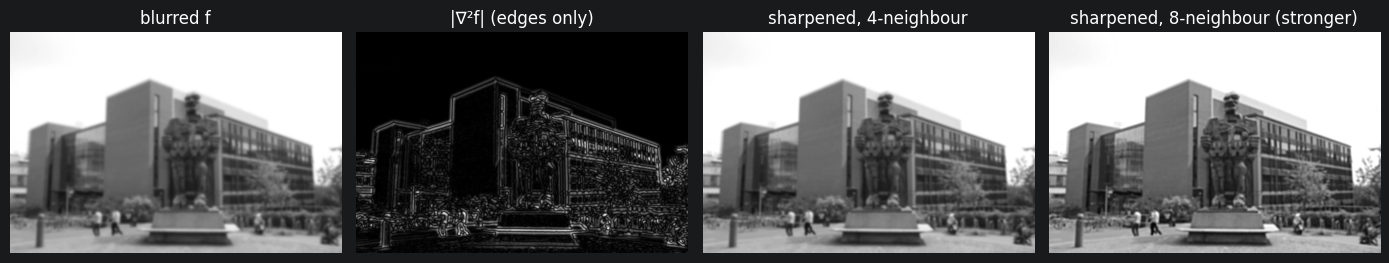

In [50]:
# The scan line from slide 61
line = np.array([6, 6, 6, 6, 5, 4, 3, 2, 1, 1, 1, 1, 1, 1, 6, 6, 6, 6, 6], float)
d1 = line[1:] - line[:-1]                       # f(x+1) - f(x)
d2 = line[2:] + line[:-2] - 2 * line[1:-1]      # f(x+1) + f(x-1) - 2f(x)
print("scan line :", line.astype(int))
print("1st deriv :", d1.astype(int))
print("2nd deriv :   ", d2.astype(int))
print("-> 1st derivative is non-zero ALONG the ramp; 2nd is non-zero only at its start/end")

lap4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)
lap8 = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float32)

blurred = cv2.GaussianBlur(f, (0, 0), 2)               # start from a soft image, like the moon slide
lap_img = cv2.filter2D(blurred, -1, lap4)
sharp4 = np.clip(blurred - lap_img, 0, 1)              # g = f + c·∇²f with c = -1
sharp8 = np.clip(blurred - cv2.filter2D(blurred, -1, lap8), 0, 1)

# cv2.Laplacian computes the same ∇²f
assert np.allclose(cv2.Laplacian(blurred, cv2.CV_32F, ksize=1), lap_img, atol=1e-5)

show([blurred, np.abs(lap_img) / np.abs(lap_img).max(), sharp4, sharp8],
     ["blurred f", "|∇²f| (edges only)", "sharpened, 4-neighbour", "sharpened, 8-neighbour (stronger)"], size=3.5)

## 17. The payoff: this IS what a CNN layer does

Your Week 7 CNN starts with `nn.Conv2d(3, 8, 3)`: **eight 3×3 kernels** slid over the image with exactly the formula from Section 11. The only difference is that **nobody hand-designs the weights**. Training (`loss.backward()` + `optimizer.step()`) learns them. A trained network's first layer typically ends up with kernels that look like the blur and edge filters from this week.

Below, a `Conv2d` layer is loaded with this week's kernels by hand, to prove it's the same operation.

input: (1, 1, 400, 600) -> output: (1, 3, 400, 600)


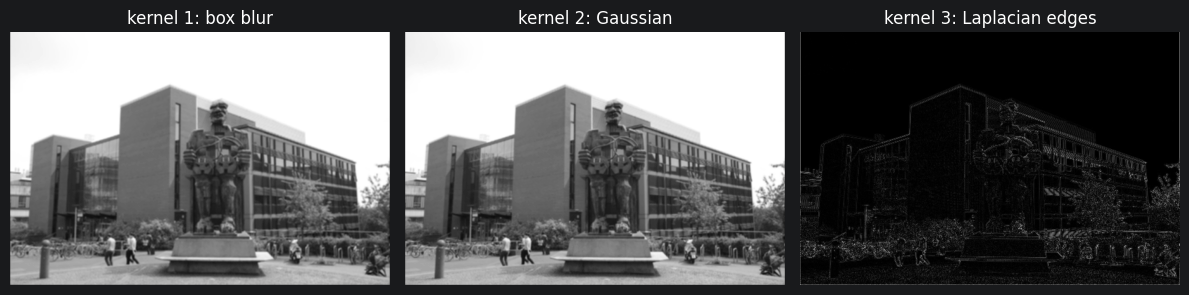

In a real CNN these 3×3 weights start random and are LEARNED from data.


In [51]:
import torch.nn as nn

conv = nn.Conv2d(in_channels=1, out_channels=3, kernel_size=3, padding=1, bias=False)
with torch.no_grad():
    conv.weight[0, 0] = torch.full((3, 3), 1 / 9)                          # box blur (Section 13)
    conv.weight[1, 0] = torch.from_numpy(gaussian_kernel(3, 1.0)[0]).float()  # Gaussian (Section 14)
    conv.weight[2, 0] = torch.from_numpy(lap4)                             # Laplacian (Section 16)

x_in = torch.from_numpy(f)[None, None]          # (batch=1, channels=1, H, W)
with torch.no_grad():
    out = conv(x_in)                             # (1, 3, H, W): one feature map per kernel
print("input:", tuple(x_in.shape), "-> output:", tuple(out.shape))

maps = out[0].numpy()
show([maps[0], maps[1], np.abs(maps[2]) / np.abs(maps[2]).max()],
     ["kernel 1: box blur", "kernel 2: Gaussian", "kernel 3: Laplacian edges"], size=4)
print("In a real CNN these 3×3 weights start random and are LEARNED from data.")

---
## Cheat sheet — every equation in one place

| Topic | Equation | One-line meaning | Code |
|---|---|---|---|
| Image formation | $f = i\cdot r$ | light × surface | – |
| Averaging K images | $\sigma^2_{\bar g}=\sigma^2_\eta/K$ | more shots → less noise | `np.mean(stack, 0)` |
| Subtraction | $d=f-g$ | what changed | `cv2.absdiff` |
| Product | $p=f\cdot g$ | mask a region | `img * mask` |
| Division | $v=f/g$ | remove uneven light | `f / g` |
| Negative | $s=L-1-z$ | invert brightness | `255 - img` |
| Euclidean / D4 / D8 | $\sqrt{\Delta x^2+\Delta y^2}$ / $\lvert\Delta x\rvert+\lvert\Delta y\rvert$ / $\max$ | three ways to measure distance | `cv2.distanceTransform` |
| N4 / N8 adjacency | edge / edge+corner neighbours | changes object counts | `cv2.connectedComponents(..., connectivity=4/8)` |
| Affine transform | $[x',y',1]^T = A[x,y,1]^T$ | move/rotate/scale/shear | `cv2.warpAffine` |
| Normalised histogram | $p(r_k)=n_k/MN$ | brightness probabilities | `cv2.calcHist` |
| Contrast stretch | $s=(L-1)\frac{r-r_{min}}{r_{max}-r_{min}}$ | linear stretch | – |
| Equalisation | $T(r_k)=(L-1)\sum_{j\le k}p(r_j)$ | CDF mapping | `cv2.equalizeHist` |
| Correlation | $\sum w(s,t)f(x+s,y+t)$ | slide & sum products | `cv2.filter2D`, `F.conv2d` |
| Convolution | correlation with $w$ rotated 180° | – | `np.convolve` |
| Degradation | $g = h\star f + \eta$ | blur + noise | – |
| Arithmetic mean | $\frac{1}{mn}\sum g$ | box blur | `cv2.blur` |
| Geometric mean | $(\prod g)^{1/mn}$ | – | – |
| Harmonic mean | $mn/\sum(1/g)$ | salt ✓ pepper ✗ | – |
| Contraharmonic | $\sum g^{Q+1}/\sum g^{Q}$ | $Q>0$ pepper, $Q<0$ salt | – |
| Gaussian | $\frac1k e^{-(s^2+t^2)/2\sigma^2}$ | natural blur | `cv2.GaussianBlur` |
| Median | median of window | **salt & pepper** | `cv2.medianBlur` |
| Max / Min | max / min of window | pepper / salt | `cv2.dilate` / `cv2.erode` |
| Midpoint | ½(max+min) | Gaussian/uniform | – |
| 1st / 2nd derivative | $f(x{+}1)-f(x)$ / $f(x{+}1)+f(x{-}1)-2f(x)$ | rate of change | – |
| Laplacian | $\sum N_4 - 4f$ | edges in all directions | `cv2.Laplacian` |
| Sharpen | $g=f-\nabla^2 f$ | add edges back | `cv2.filter2D` |

### Which filter for which noise? (likely exam question)

| Noise | Best choice | Avoid |
|---|---|---|
| Gaussian / uniform | Gaussian, arithmetic or geometric mean, midpoint | – |
| Salt only | min, harmonic, contraharmonic $Q<0$ | contraharmonic $Q>0$ |
| Pepper only | max, contraharmonic $Q>0$ | harmonic, contraharmonic $Q<0$ |
| **Salt & pepper** | **median** | mean filters (they smear the dots) |